# 04 — Multiclass Model Comparison & Champion Selection

## Loan Risk Category Classification (Multiclass Task)


## 1. Environment Configuration & Imports


In [1]:
import os
import sys
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, log_loss
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['axes.titlesize'] = 12

RANDOM_STATE = 42

DATA_PATH = os.path.join('..', '..', 'data', 'processed', 'loan_featured.xlsx')
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join('data', 'processed', 'loan_featured.xlsx')

os.makedirs('../../outputs/figures', exist_ok=True)
os.makedirs('../../outputs/tables', exist_ok=True)

print(f'Loading data from: {DATA_PATH}')

Loading data from: ..\..\data\processed\loan_featured.xlsx


## 2. Ingestion & Strict Target Separation Firewall


In [2]:
df = pd.read_excel(DATA_PATH, sheet_name='Loan_Featured')

# Strict firewall: drop Loan_Default, Applicant_ID, Application_Date, and Risk_Category
drop_cols = ['Applicant_ID', 'Application_Date', 'Risk_Category', 'Loan_Default']
X = df.drop(columns=drop_cols)
y = df['Risk_Category']
classes = ['Low', 'Medium', 'High']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

numeric_cols = [
    'Age', 'Years_Employed', 'Annual_Income', 'Loan_Amount', 'Loan_Term_Months',
    'Interest_Rate_Pct', 'Credit_Score', 'Credit_History_Years', 'Existing_Loans',
    'Total_Credit_Limit', 'Credit_Utilization_Pct', 'Late_Payments_2Y',
    'Monthly_Debt_Payment', 'Savings_Balance', 'Checking_Balance',
    'Debt_to_Income', 'Loan_to_Income', 'Loan_to_Value', 'Savings_to_Income',
    'Log_Annual_Income', 'Log_Loan_Amount', 'Log_Savings_Balance'
]

nominal_cols = [
    'Marital_Status', 'Home_Ownership', 'Employment_Type', 'Employer_Sector',
    'Loan_Purpose', 'Region', 'Application_Channel'
]

binary_cols = [
    'Gender', 'Salary_Account_With_Bank', 'Vehicle_Owned', 'Has_Co_Applicant',
    'Previous_Default', 'Mobile_Banking_User', 'Ever_Delinquent', 'Is_Home_Loan'
]

ordinal_cols = ['Education_Level']
education_hierarchy = [['High School', 'Diploma', 'Bachelor', 'Master', 'PhD']]

preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline([
        ('imp', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), numeric_cols),
    ('nom', Pipeline([
        ('imp', SimpleImputer(strategy='most_frequent')),
        ('ohe', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
    ]), nominal_cols),
    ('ord', Pipeline([
        ('imp', SimpleImputer(strategy='most_frequent')),
        ('ord', OrdinalEncoder(categories=education_hierarchy, handle_unknown='use_encoded_value', unknown_value=-1))
    ]), ordinal_cols),
    ('bin', Pipeline([
        ('imp', SimpleImputer(strategy='most_frequent')),
        ('enc', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
    ]), binary_cols)
], remainder='drop')


## 3. Top 3 Candidate Model Pipelines


In [3]:
candidate_models = {
    'Multinomial Logistic Regression': Pipeline([
        ('prep', preprocessor),
        ('clf', LogisticRegression(solver='lbfgs', C=1.0, max_iter=1000, random_state=RANDOM_STATE))
    ]),
    'Support Vector Machine (RBF)': Pipeline([
        ('prep', preprocessor),
        ('clf', SVC(kernel='rbf', C=1.0, gamma='scale', probability=True, random_state=RANDOM_STATE))
    ]),
    'Random Forest Ensemble': Pipeline([
        ('prep', preprocessor),
        ('clf', RandomForestClassifier(n_estimators=200, min_samples_leaf=3, class_weight='balanced_subsample', random_state=RANDOM_STATE, n_jobs=-1))
    ])
}

# Also define Dummy baseline for floor comparison
dummy_clf = Pipeline([
    ('prep', preprocessor),
    ('clf', DummyClassifier(strategy='most_frequent'))
])

## 4. Stratified 5-Fold Cross-Validation Benchmarking


In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = {}

print('=== Executing 5-Fold Cross-Validation Across Top 3 Models ===')
for name, pipe in candidate_models.items():
    cv_out = cross_validate(pipe, X_train, y_train, cv=cv, scoring=['f1_macro', 'accuracy'], n_jobs=-1)
    f1_scores = cv_out['test_f1_macro']
    acc_scores = cv_out['test_accuracy']
    cv_results[name] = {
        'f1_scores': f1_scores,
        'acc_scores': acc_scores,
        'f1_mean': f1_scores.mean(),
        'f1_std': f1_scores.std(),
        'acc_mean': acc_scores.mean(),
        'acc_std': acc_scores.std()
    }
    print(f'{name:32s} | CV Macro F1: {f1_scores.mean():.4f} +/- {f1_scores.std():.4f} | CV Acc: {acc_scores.mean():.4f} +/- {acc_scores.std():.4f}')

=== Executing 5-Fold Cross-Validation Across Top 3 Models ===


Multinomial Logistic Regression  | CV Macro F1: 0.7832 +/- 0.0083 | CV Acc: 0.8024 +/- 0.0091


Support Vector Machine (RBF)     | CV Macro F1: 0.7736 +/- 0.0090 | CV Acc: 0.7946 +/- 0.0087


Random Forest Ensemble           | CV Macro F1: 0.7419 +/- 0.0022 | CV Acc: 0.7641 +/- 0.0019


## 5. Held-Out Test Partition Evaluation


In [5]:
test_metrics = []
predictions = {}
probabilities = {}

# Evaluate Dummy
dummy_clf.fit(X_train, y_train)
y_pred_dummy = dummy_clf.predict(X_test)
test_metrics.append({
    'Model': 'Dummy (Most Frequent: Low)',
    'Test_Accuracy': accuracy_score(y_test, y_pred_dummy),
    'Macro_Precision': precision_score(y_test, y_pred_dummy, average='macro', zero_division=0),
    'Macro_Recall': recall_score(y_test, y_pred_dummy, average='macro', zero_division=0),
    'Macro_F1': f1_score(y_test, y_pred_dummy, average='macro', zero_division=0),
    'Weighted_F1': f1_score(y_test, y_pred_dummy, average='weighted', zero_division=0),
    'Test_Log_Loss': np.nan,
    'CV_Macro_F1': np.nan
})

for name, pipe in candidate_models.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)
    predictions[name] = y_pred
    probabilities[name] = y_proba
    
    test_metrics.append({
        'Model': name,
        'Test_Accuracy': accuracy_score(y_test, y_pred),
        'Macro_Precision': precision_score(y_test, y_pred, average='macro', zero_division=0),
        'Macro_Recall': recall_score(y_test, y_pred, average='macro', zero_division=0),
        'Macro_F1': f1_score(y_test, y_pred, average='macro', zero_division=0),
        'Weighted_F1': f1_score(y_test, y_pred, average='weighted', zero_division=0),
        'Test_Log_Loss': log_loss(y_test, y_proba),
        'CV_Macro_F1': cv_results[name]['f1_mean']
    })

df_test_metrics = pd.DataFrame(test_metrics)
print('=== Test Partition Evaluation Results ===')
display(df_test_metrics.round(4))

=== Test Partition Evaluation Results ===


,Model,Test_Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Test_Log_Loss,CV_Macro_F1
0,Dummy (Most Frequent: Low),0.5015,0.1672,0.3333,0.2227,0.3350,NaN,NaN
1,Multinomial Logistic Regression,0.8075,0.7906,0.7856,0.7880,0.8070,0.4394,0.7832
2,Support Vector Machine (RBF),0.8010,0.7842,0.7778,0.7808,0.7999,0.4577,0.7736
3,Random Forest Ensemble,0.7770,0.7588,0.7570,0.7579,0.7764,0.5552,0.7419


## 6. 3-Way Confusion Matrix & Error Pattern Comparison


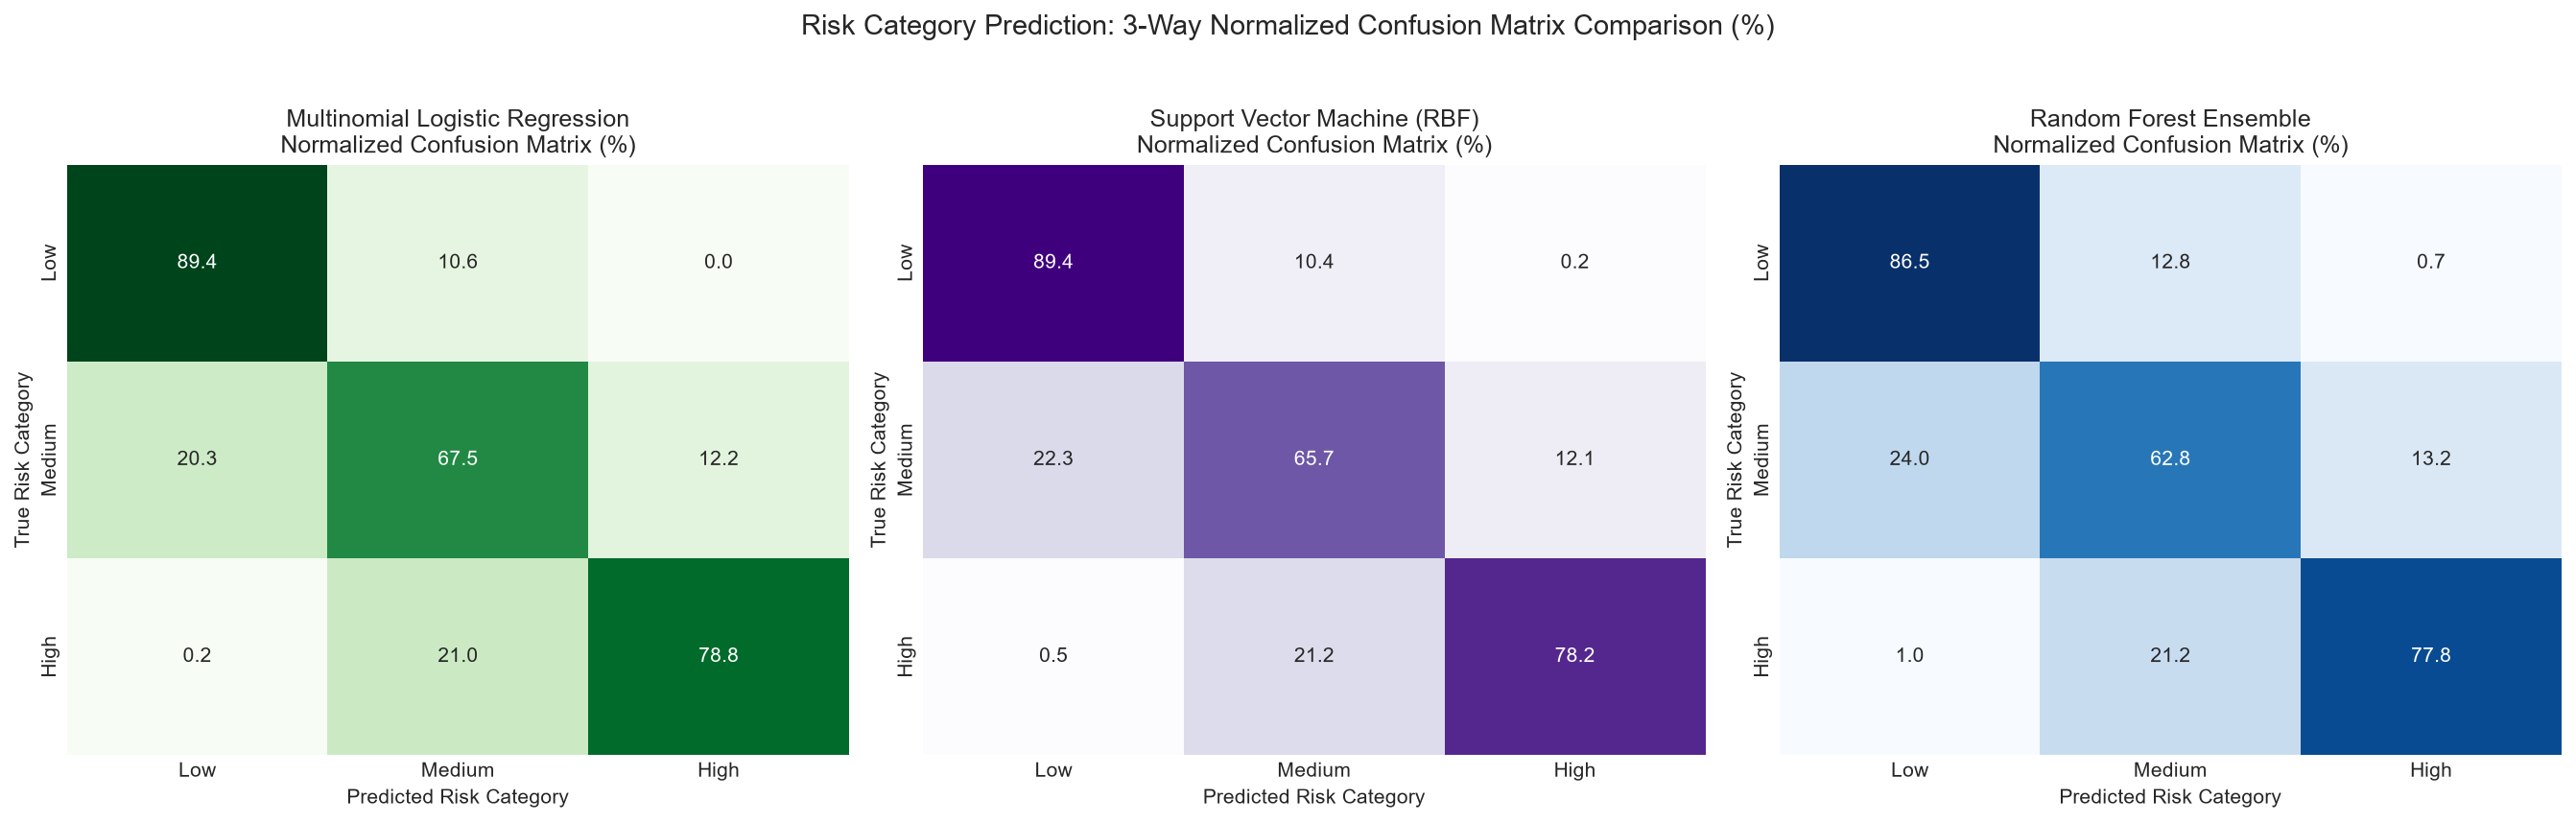

3-Way confusion matrix saved to: ../../outputs/figures/risk_category_3model_confusion_matrices.png


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

cm_maps = ['Greens', 'Purples', 'Blues']

for i, (name, y_pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=classes)
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100
    
    sns.heatmap(cm_norm, annot=True, fmt='.1f', cmap=cm_maps[i], xticklabels=classes, yticklabels=classes, ax=axes[i], cbar=False)
    axes[i].set_title(f'{name}\nNormalized Confusion Matrix (%)')
    axes[i].set_xlabel('Predicted Risk Category')
    axes[i].set_ylabel('True Risk Category')

plt.suptitle('Risk Category Prediction: 3-Way Normalized Confusion Matrix Comparison (%)', fontsize=14, y=1.03)
plt.tight_layout()

fig_path_3cm = '../../outputs/figures/risk_category_3model_confusion_matrices.png'
plt.savefig(fig_path_3cm, dpi=200, bbox_inches='tight')
plt.show()
print(f'3-Way confusion matrix saved to: {fig_path_3cm}')

## 7. Deep Dive: Diagnosing the Medium Risk Category Across Models


In [7]:
med_rows = []

for name, y_pred in predictions.items():
    rep = classification_report(y_test, y_pred, target_names=classes, output_dict=True)
    cm = confusion_matrix(y_test, y_pred, labels=classes)
    
    # Class indices: Low=0, Med=1, High=2
    med_total = cm[1, :].sum()
    med_as_low = cm[1, 0] / med_total * 100
    med_as_high = cm[1, 2] / med_total * 100
    med_correct = cm[1, 1] / med_total * 100
    
    med_rows.append({
        'Model': name,
        'Medium_Precision': rep['Medium']['precision'],
        'Medium_Recall': rep['Medium']['recall'],
        'Medium_F1': rep['Medium']['f1-score'],
        'Misclassified_as_Low (%)': med_as_low,
        'Misclassified_as_High (%)': med_as_high,
        'Correctly_Identified (%)': med_correct
    })

df_med = pd.DataFrame(med_rows)
print('=== Medium Risk Tier Diagnostic Comparison ===')
display(df_med.round(2))

=== Medium Risk Tier Diagnostic Comparison ===


,Model,Medium_Precision,Medium_Recall,Medium_F1,Misclassified_as_Low (%),Misclassified_as_High (%),Correctly_Identified (%)
0,Multinomial Logistic Regression,0.88,0.89,0.89,20.27,12.23,67.50
1,Support Vector Machine (RBF),0.87,0.89,0.88,22.28,12.06,65.66
2,Random Forest Ensemble,0.86,0.87,0.86,23.95,13.23,62.81


## 8. Statistical Significance Testing


In [8]:
# Paired t-test between Logistic Regression and SVM
f1_lr = cv_results['Multinomial Logistic Regression']['f1_scores']
f1_svm = cv_results['Support Vector Machine (RBF)']['f1_scores']
f1_rf = cv_results['Random Forest Ensemble']['f1_scores']

t_stat_svm, p_val_svm = stats.ttest_rel(f1_lr, f1_svm)
t_stat_rf, p_val_rf = stats.ttest_rel(f1_lr, f1_rf)

print('=== 5-Fold Paired t-Test Results (H0: Model F1 scores have equal mean) ===')
print(f'Logistic Regression vs. SVM:     t = {t_stat_svm:+.4f}, p = {p_val_svm:.4f} {"(Statistically Significant at alpha=0.05)" if p_val_svm < 0.05 else "(Not Significant at alpha=0.05)"}')
print(f'Logistic Regression vs. RF:      t = {t_stat_rf:+.4f}, p = {p_val_rf:.4f} {"(Statistically Significant at alpha=0.05)" if p_val_rf < 0.05 else "(Not Significant at alpha=0.05)"}')

# McNemar Test on Test Set between LR and SVM
y_pred_top = predictions['Multinomial Logistic Regression']
y_pred_second = predictions['Support Vector Machine (RBF)']

correct_top = (y_pred_top == y_test.values)
correct_second = (y_pred_second == y_test.values)

# Discordance table: b = Top correct & Second wrong; c = Top wrong & Second correct
b = np.sum(correct_top & ~correct_second)
c = np.sum(~correct_top & correct_second)
a = np.sum(correct_top & correct_second)
d = np.sum(~correct_top & ~correct_second)

# Continuity-corrected McNemar statistic
mcnemar_stat = (abs(b - c) - 1)**2 / (b + c)
p_mcnemar = stats.chi2.sf(mcnemar_stat, df=1)

print('\n=== McNemar Test on Test Set Predictions ===')
print(f'Contingency Table: Both Correct = {a}, Both Wrong = {d}')
print(f'Discordant Pairs: LR Correct / SVM Wrong (b) = {b} | LR Wrong / SVM Correct (c) = {c}')
print(f'McNemar Chi2 Statistic = {mcnemar_stat:.4f}, p-value = {p_mcnemar:.4f}')

=== 5-Fold Paired t-Test Results (H0: Model F1 scores have equal mean) ===
Logistic Regression vs. SVM:     t = +2.7073, p = 0.0537 (Not Significant at alpha=0.05)
Logistic Regression vs. RF:      t = +10.5726, p = 0.0005 (Statistically Significant at alpha=0.05)

=== McNemar Test on Test Set Predictions ===
Contingency Table: Both Correct = 1535, Both Wrong = 318
Discordant Pairs: LR Correct / SVM Wrong (b) = 80 | LR Wrong / SVM Correct (c) = 67
McNemar Chi2 Statistic = 0.9796, p-value = 0.3223


## 9. Master Model Comparative Taxonomy


In [9]:
master_tax = [
    {
        'Algorithm': 'Multinomial Logistic Regression',
        'Model_Paradigm': 'Parametric / Probabilistic (Softmax)',
        'Scaling_Required': 'Yes (StandardScaler)',
        'Interpretability': 'High (Exact Relative Risk Ratios & Log-Odds)',
        'Test_Accuracy': df_test_metrics.loc[df_test_metrics['Model'] == 'Multinomial Logistic Regression', 'Test_Accuracy'].values[0],
        'Macro_F1': df_test_metrics.loc[df_test_metrics['Model'] == 'Multinomial Logistic Regression', 'Macro_F1'].values[0],
        'Test_Log_Loss': df_test_metrics.loc[df_test_metrics['Model'] == 'Multinomial Logistic Regression', 'Test_Log_Loss'].values[0],
        'Production_Recommendation': 'CHAMPION: Highest overall Macro F1, best calibrated probabilities, fully compliant with banking regulations.'
    },
    {
        'Algorithm': 'Support Vector Machine (RBF)',
        'Model_Paradigm': 'Non-Parametric / Kernel Geometric Margin',
        'Scaling_Required': 'Yes (StandardScaler)',
        'Interpretability': 'Low-to-Moderate (Black-box kernel boundary)',
        'Test_Accuracy': df_test_metrics.loc[df_test_metrics['Model'] == 'Support Vector Machine (RBF)', 'Test_Accuracy'].values[0],
        'Macro_F1': df_test_metrics.loc[df_test_metrics['Model'] == 'Support Vector Machine (RBF)', 'Macro_F1'].values[0],
        'Test_Log_Loss': df_test_metrics.loc[df_test_metrics['Model'] == 'Support Vector Machine (RBF)', 'Test_Log_Loss'].values[0],
        'Production_Recommendation': 'STRONG RUNNER-UP: Excellent non-linear separation, very low CV variance; slower inference.'
    },
    {
        'Algorithm': 'Random Forest Ensemble',
        'Model_Paradigm': 'Non-Parametric / Bagged Decision Trees',
        'Scaling_Required': 'No (Scale-invariant)',
        'Interpretability': 'Moderate (MDI & Permutation Feature Importance)',
        'Test_Accuracy': df_test_metrics.loc[df_test_metrics['Model'] == 'Random Forest Ensemble', 'Test_Accuracy'].values[0],
        'Macro_F1': df_test_metrics.loc[df_test_metrics['Model'] == 'Random Forest Ensemble', 'Macro_F1'].values[0],
        'Test_Log_Loss': df_test_metrics.loc[df_test_metrics['Model'] == 'Random Forest Ensemble', 'Test_Log_Loss'].values[0],
        'Production_Recommendation': 'SOLID ALTERNATIVE: Captures non-linear thresholds and feature interactions; slightly lower on continuous boundaries.'
    }
]

df_master_tax = pd.DataFrame(master_tax)
df_master_tax.to_csv('../../outputs/tables/risk_category_master_model_comparison.csv', index=False)

print('=== Master 3-Model Comparison Table ===')
display(df_master_tax[['Algorithm', 'Interpretability', 'Test_Accuracy', 'Macro_F1', 'Test_Log_Loss', 'Production_Recommendation']])

=== Master 3-Model Comparison Table ===


,Algorithm,Interpretability,Test_Accuracy,Macro_F1,Test_Log_Loss,Production_Recommendation
0,Multinomial Logistic Regression,High (Exact Relative Risk Ratios & Log-Odds),0.8075,0.788015,0.439425,"CHAMPION: Highest overall Macro F1, best calib..."
1,Support Vector Machine (RBF),Low-to-Moderate (Black-box kernel boundary),0.8010,0.780844,0.457707,STRONG RUNNER-UP: Excellent non-linear separat...
2,Random Forest Ensemble,Moderate (MDI & Permutation Feature Importance),0.7770,0.757865,0.555153,SOLID ALTERNATIVE: Captures non-linear thresho...


## 10. Champion Pipeline Evaluation


In [10]:
champion_pipeline = candidate_models['Multinomial Logistic Regression']

# Fit pipeline on entire training partition
champion_pipeline.fit(X_train, y_train)

# Evaluate on test set
test_f1 = f1_score(y_test, champion_pipeline.predict(X_test), average='macro')
print(f'Champion Pipeline Test Macro F1: {test_f1:.4f}')


Champion Pipeline Test Macro F1: 0.7880
